--- EVALUATING TRAINING SET ---
Processing 216 match files from Training/Mirage...


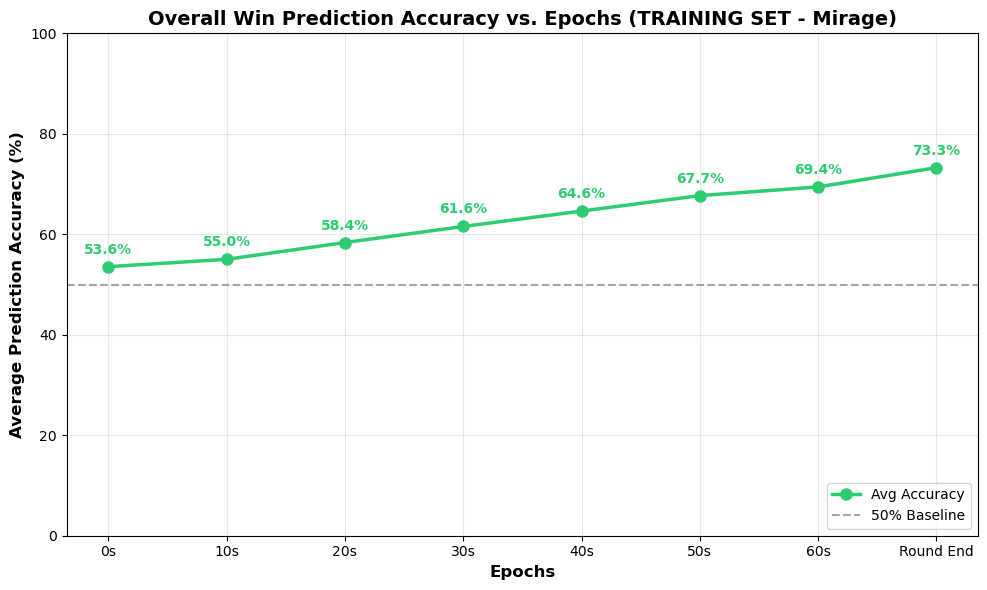


--- EVALUATING TESTING SET ---
Processing 54 match files from Testing/Mirage...


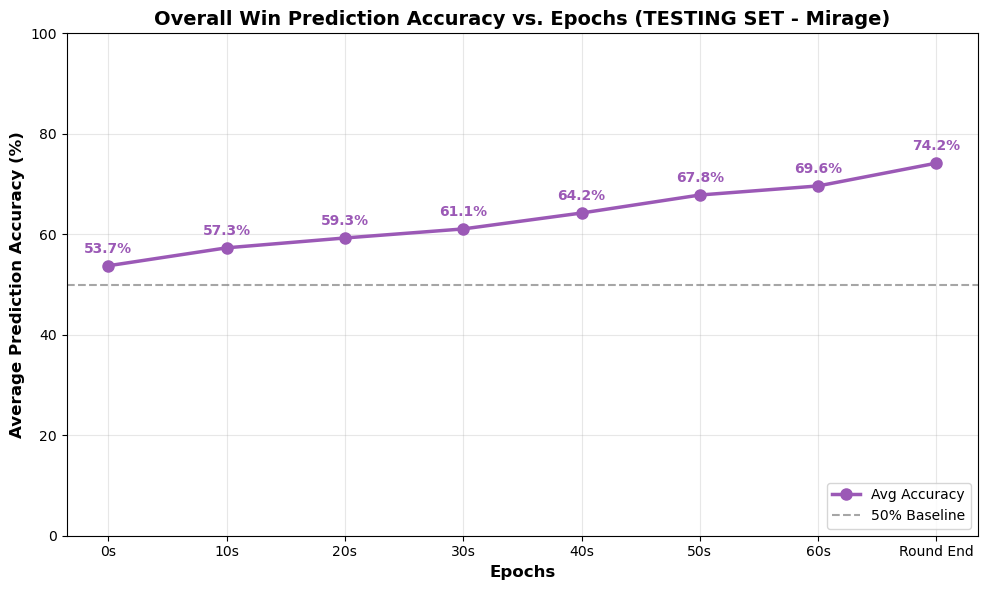

In [1]:
import glob
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# 1. CONFIGURATION & PATHS
# ==========================================
TRAIN_RESULTS_DIR = Path(r"F:\Research_Data_Public\Esports\CSDATA\DataScience\CS2_Project\Results\STOMs\WP_DAC_01\Training\Mirage")
TEST_RESULTS_DIR = Path(r"F:\Research_Data_Public\Esports\CSDATA\DataScience\CS2_Project\Results\STOMs\WP_DAC_01\Testing\Mirage")

EPOCHS = ["0", "10", "20", "30", "40", "50", "60", "End"]

# ==========================================
# 2. DATA RETRIEVAL & AGGREGATION
# ==========================================
def get_average_accuracy(results_dir):
    """
    Parses all match result CSVs in the directory, extracts Row 4 (Accuracy), 
    and computes the average accuracy across all matches per epoch.
    """
    if not results_dir.exists():
        print(f"Error: Directory does not exist -> {results_dir}")
        return None

    csv_files = list(results_dir.glob("*.csv"))
    if not csv_files:
        print(f"No CSV files found in -> {results_dir}")
        return None

    print(f"Processing {len(csv_files)} match files from {results_dir.parent.name}/{results_dir.name}...")

    # Dictionary to hold all accuracy values for each epoch across all matches
    epoch_accuracies = {e: [] for e in EPOCHS}

    for filepath in csv_files:
        try:
            df = pl.read_csv(filepath)
            
            # Extract Row 4: "Row 4: Prediction Accuracy"
            # Using polars filter to ensure we grab the correct row regardless of index
            acc_row = df.filter(pl.col("Metric").str.contains("Row 4"))
            
            if acc_row.is_empty():
                continue
                
            row_dict = acc_row.to_dicts()[0]
            
            for e in EPOCHS:
                col_name = f"Epoch_{e}"
                if col_name in row_dict:
                    # Convert to percentage
                    accuracy_val = float(row_dict[col_name]) * 100 
                    epoch_accuracies[e].append(accuracy_val)
                    
        except Exception as ex:
            print(f"Error processing {filepath.name}: {ex}")

    # Compute averages
    avg_accuracies = []
    for e in EPOCHS:
        if epoch_accuracies[e]:
            avg_accuracies.append(np.mean(epoch_accuracies[e]))
        else:
            avg_accuracies.append(0.0)

    return avg_accuracies

# ==========================================
# 3. VISUALIZATION
# ==========================================
def plot_overall_accuracy(avg_accuracies, title, color):
    """Generates a line plot for average accuracy vs. epochs."""
    if not avg_accuracies:
        return

    plt.figure(figsize=(10, 6))
    
    # Plotting the data
    x_labels = [f"{e}s" if e != "End" else "Round End" for e in EPOCHS]
    plt.plot(x_labels, avg_accuracies, marker='o', markersize=8, color=color, linewidth=2.5, label="Avg Accuracy")
    
    # Formatting
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel("Epochs", fontsize=12, fontweight='bold')
    plt.ylabel("Average Prediction Accuracy (%)", fontsize=12, fontweight='bold')
    plt.ylim(0, 100)
    plt.axhline(50, color='gray', linestyle='--', alpha=0.7, label="50% Baseline")
    
    # Adding data labels to points
    for i, acc in enumerate(avg_accuracies):
        plt.text(i, acc + 2, f"{acc:.1f}%", ha='center', va='bottom', fontsize=10, fontweight='bold', color=color)

    plt.grid(True, alpha=0.3)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

# ==========================================
# MAIN EXECUTION
# ==========================================
if __name__ == "__main__":
    # --- Step 1, 2 & 3: Training Data ---
    print("--- EVALUATING TRAINING SET ---")
    train_avg_acc = get_average_accuracy(TRAIN_RESULTS_DIR)
    if train_avg_acc:
        plot_overall_accuracy(
            train_avg_acc, 
            "Overall Win Prediction Accuracy vs. Epochs (TRAINING SET - Mirage)", 
            color="#2ecc71" # Green
        )

    # --- Step 4: Testing Data ---
    print("\n--- EVALUATING TESTING SET ---")
    test_avg_acc = get_average_accuracy(TEST_RESULTS_DIR)
    if test_avg_acc:
        plot_overall_accuracy(
            test_avg_acc, 
            "Overall Win Prediction Accuracy vs. Epochs (TESTING SET - Mirage)", 
            color="#9b59b6" # Purple
        )